# RBM-Based Probabilistic Anomaly Detection for Automated Data Quality Assessment

**Course topics covered:** Restricted Boltzmann Machines (RBMs) · Markov Networks (undirected graphical models) · Markov Chains (Gibbs sampling) · energy-based probabilistic modelling

**Aim.** Train an RBM *only on normal data* so that it learns the probability distribution of "healthy" records. Any record that is unlikely under this learned distribution is flagged as an **anomaly / data-quality problem**.

**Dataset.** Wisconsin Diagnostic Breast Cancer data bundled with scikit-learn (569 rows, 30 numeric features). Benign records play the role of *normal* data and malignant records play the role of *anomalies*. We additionally inject **synthetic data-quality faults** (noise, outliers, shuffled columns, missing values filled with 0) to test the detector as an automated data-quality tool. This is an educational experiment, not a medical tool.

**Pipeline**
1. Load data and split (train on normal rows only) 
2. Define the RBM (Bernoulli and Gaussian-Bernoulli versions) 
3. Train with Contrastive Divergence 
4. Score samples with **free energy** and detect anomalies 
5. Compare Bernoulli RBM vs Gaussian-Bernoulli RBM vs a PCA baseline 
6. Data-quality experiment with injected corruption 
7. Explain *which features* look wrong (per-feature diagnosis) 
8. Markov-chain view: Gibbs sampling pulls anomalies toward normal data 
9. Hidden units, then **deployment** (saved model, CSV checker, web app)
10. Conclusion and viva notes

## 1. Imports and setup

In [1]:
import random, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)          # one random generator used everywhere -> reproducible
plt.rcParams["figure.dpi"] = 100
print("Setup done. (Pure NumPy implementation - no deep-learning framework needed.)")

Setup done. (Pure NumPy implementation - no deep-learning framework needed.)


## 2. Load data and split

We treat **malignant = anomaly (1)** and **benign = normal (0)**.

* The RBM is trained **only on normal training rows** (unsupervised: it never sees an anomaly).
* The validation set is used to choose the threshold and the model size.
* The test set is used once for the final report.
* Scalers are fitted on normal training data only, to avoid data leakage.

In [2]:
data = load_breast_cancer()
X_all = data.data.astype(np.float64)
feature_names = list(data.feature_names)
is_anom = (data.target == 0).astype(int)        # sklearn: 0 = malignant, 1 = benign  ->  anomaly = malignant

print("Dataset shape:", X_all.shape, "| anomalies:", is_anom.sum(), "| normal:", (is_anom == 0).sum())

X_train, X_tmp, a_train, a_tmp = train_test_split(X_all, is_anom, test_size=.30, random_state=SEED, stratify=is_anom)
X_val,  X_test, a_val, a_test  = train_test_split(X_tmp, a_tmp, test_size=.50, random_state=SEED, stratify=a_tmp)

X_train_normal = X_train[a_train == 0]           # RBM training data = normal rows only

# Scaler for the Gaussian RBM: zero mean, unit variance (fit on normal training data only)
std_scaler = StandardScaler().fit(X_train_normal)
# Scaler for the Bernoulli RBM: values squeezed into [0,1]
mm_scaler  = MinMaxScaler().fit(X_train_normal)

prep_gauss = lambda A: std_scaler.transform(A)
prep_bern  = lambda A: np.clip(mm_scaler.transform(A), 0, 1)

print(f"Normal training rows: {len(X_train_normal)} | validation: {len(X_val)} ({a_val.sum()} anomalies) | "
      f"test: {len(X_test)} ({a_test.sum()} anomalies)")
display(pd.DataFrame(X_all[:5, :6], columns=feature_names[:6]))

Dataset shape: (569, 30) | anomalies: 212 | normal: 357
Normal training rows: 250 | validation: 85 (32 anomalies) | test: 86 (32 anomalies)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
0,17.99,10.38,122.80,1001.0,0.11840,0.27760
1,20.57,17.77,132.90,1326.0,0.08474,0.07864
2,19.69,21.25,130.00,1203.0,0.10960,0.15990
3,11.42,20.38,77.58,386.1,0.14250,0.28390
4,20.29,14.34,135.10,1297.0,0.10030,0.13280


## 3. The Restricted Boltzmann Machine

An RBM is an **undirected graphical model (Markov network)** with two layers: visible units **v** (our 30 features) and hidden units **h** (learned binary features). There are connections *only between* layers, never within a layer, which makes the conditional distributions easy:

$$P(h_j=1\mid v)=\sigma\Big(c_j+\sum_i v_i W_{ij}\Big)\qquad P(v\mid h)\ \text{depends on } W h + b$$

The model assigns an **energy** to every configuration; low energy means high probability: $P(v,h)=e^{-E(v,h)}/Z$.

| Version | Visible units | Energy $E(v,h)$ | Free energy $F(v)$ |
|---|---|---|---|
| Bernoulli–Bernoulli | binary / values in [0,1] | $-b^\top v - c^\top h - v^\top W h$ | $-b^\top v-\sum_j \mathrm{softplus}(c_j+v^\top W_{:,j})$ |
| **Gaussian–Bernoulli** | real-valued (standardised) | $\tfrac12\lVert v-b\rVert^2 - c^\top h - v^\top W h$ | $\tfrac12\lVert v-b\rVert^2-\sum_j \mathrm{softplus}(c_j+v^\top W_{:,j})$ |

Summing out the hidden units gives the **free energy** $F(v)=-\log\sum_h e^{-E(v,h)}$, so $P(v)\propto e^{-F(v)}$.
The partition function $Z$ is intractable, but we do not need it: **ranking samples by free energy is the same as ranking them by probability.**

**Anomaly score = free energy.** Normal data → low free energy. Unusual data → high free energy.

**Training: Contrastive Divergence (CD-k).** We move the weights to lower the energy of real data (*positive phase*) and raise the energy of the model's own reconstructions (*negative phase*). The reconstructions are produced by a short **Gibbs sampling chain**, which is a Markov chain: $v \to h \to v \to h\dots$

In [3]:
def sigmoid(x):  return 1.0 / (1.0 + np.exp(-x))
def softplus(x): return np.logaddexp(0, x)

class RBM:
    """Restricted Boltzmann Machine trained with Contrastive Divergence.
    visible = 'bernoulli' (inputs in [0,1])  or  'gaussian' (standardised real-valued inputs, unit variance)."""
    def __init__(self, n_vis, n_hid, visible="gaussian", lr=0.01, k=1, weight_decay=1e-4, momentum=0.5):
        self.visible, self.lr, self.k, self.wd, self.mom = visible, lr, k, weight_decay, momentum
        self.W = rng.normal(0, 0.01, (n_vis, n_hid))
        self.b = np.zeros(n_vis)                 # visible bias
        self.c = np.zeros(n_hid)                 # hidden bias
        self.vW, self.vb, self.vc = np.zeros_like(self.W), np.zeros_like(self.b), np.zeros_like(self.c)

    # --- conditional distributions of the Markov network ---
    def p_h(self, v):                            # P(h=1 | v)
        return sigmoid(v @ self.W + self.c)
    def p_v(self, h):                            # mean of P(v | h)
        a = h @ self.W.T + self.b
        return a if self.visible == "gaussian" else sigmoid(a)
    def sample_h(self, p):
        return (rng.random(p.shape) < p).astype(float)

    # --- scores ---
    def free_energy(self, v):                    # F(v): higher = less probable = more anomalous
        hidden_term = softplus(v @ self.W + self.c).sum(axis=1)
        if self.visible == "gaussian":
            return 0.5 * ((v - self.b) ** 2).sum(axis=1) - hidden_term
        return -(v @ self.b) - hidden_term
    def reconstruct(self, v):                    # one up-down pass (mean-field)
        return self.p_v(self.p_h(v))

    # --- Contrastive Divergence step ---
    def cd_step(self, v0):
        ph0 = self.p_h(v0); h = self.sample_h(ph0)
        for _ in range(self.k):                  # Gibbs chain: h -> v -> h
            vk = self.p_v(h)
            phk = self.p_h(vk); h = self.sample_h(phk)
        n = len(v0)
        dW = (v0.T @ ph0 - vk.T @ phk) / n - self.wd * self.W      # positive phase - negative phase
        db = (v0 - vk).mean(axis=0)
        dc = (ph0 - phk).mean(axis=0)
        self.vW = self.mom * self.vW + self.lr * dW
        self.vb = self.mom * self.vb + self.lr * db
        self.vc = self.mom * self.vc + self.lr * dc
        self.W += self.vW; self.b += self.vb; self.c += self.vc
        return float(((vk - v0) ** 2).mean())

def train_rbm(rbm, V_train, V_monitor, epochs=300, batch=32, verbose=True, name="RBM"):
    """Train; monitor reconstruction error and free energy on held-out NORMAL rows (no anomaly labels used)."""
    hist = {"recon": [], "fe_train": [], "fe_val_normal": []}
    for ep in range(epochs):
        perm = rng.permutation(len(V_train)); errs = []
        for i in range(0, len(V_train), batch):
            errs.append(rbm.cd_step(V_train[perm[i:i + batch]]))
        hist["recon"].append(np.mean(errs))
        hist["fe_train"].append(rbm.free_energy(V_train).mean())
        hist["fe_val_normal"].append(rbm.free_energy(V_monitor).mean())
        if verbose and (ep + 1) % 50 == 0:
            print(f"{name} | epoch {ep+1:>3}/{epochs} | recon MSE={hist['recon'][-1]:.4f} | "
                  f"mean FE train={hist['fe_train'][-1]:.2f} | mean FE val-normal={hist['fe_val_normal'][-1]:.2f}")
    return rbm, hist

## 4. Train both RBMs

We train a **Bernoulli RBM** (min-max scaled data) and a **Gaussian–Bernoulli RBM** (standardised data) on normal rows only. The Gaussian version is the natural choice for continuous features, which is why we expect it to do better.

In [4]:
V_tr_b, V_va_b, V_te_b = prep_bern(X_train_normal), prep_bern(X_val), prep_bern(X_test)
V_tr_g, V_va_g, V_te_g = prep_gauss(X_train_normal), prep_gauss(X_val), prep_gauss(X_test)
val_normal_b, val_normal_g = V_va_b[a_val == 0], V_va_g[a_val == 0]

rbm_b, h_b = train_rbm(RBM(30, 16, "bernoulli", lr=0.05), V_tr_b, val_normal_b, epochs=300, name="Bernoulli RBM")
print()
rbm_g, h_g = train_rbm(RBM(30, 16, "gaussian",  lr=0.005), V_tr_g, val_normal_g, epochs=300, name="Gaussian RBM ")

Bernoulli RBM | epoch  50/300 | recon MSE=0.0242 | mean FE train=-4.93 | mean FE val-normal=-4.92
Bernoulli RBM | epoch 100/300 | recon MSE=0.0235 | mean FE train=-4.86 | mean FE val-normal=-4.82
Bernoulli RBM | epoch 150/300 | recon MSE=0.0201 | mean FE train=-5.46 | mean FE val-normal=-5.38
Bernoulli RBM | epoch 200/300 | recon MSE=0.0214 | mean FE train=-5.71 | mean FE val-normal=-5.58
Bernoulli RBM | epoch 250/300 | recon MSE=0.0202 | mean FE train=-6.16 | mean FE val-normal=-6.03
Bernoulli RBM | epoch 300/300 | recon MSE=0.0211 | mean FE train=-6.63 | mean FE val-normal=-6.50

Gaussian RBM  | epoch  50/300 | recon MSE=0.5636 | mean FE train=-4.56 | mean FE val-normal=-6.06
Gaussian RBM  | epoch 100/300 | recon MSE=0.4986 | mean FE train=-6.36 | mean FE val-normal=-7.49
Gaussian RBM  | epoch 150/300 | recon MSE=0.4549 | mean FE train=-7.42 | mean FE val-normal=-8.48
Gaussian RBM  | epoch 200/300 | recon MSE=0.4254 | mean FE train=-8.34 | mean FE val-normal=-9.30
Gaussian RBM  | epo

### Training curves
Reconstruction error should fall. The mean free energy of *held-out normal* data should drop and stay close to the training curve (a large gap would mean overfitting).

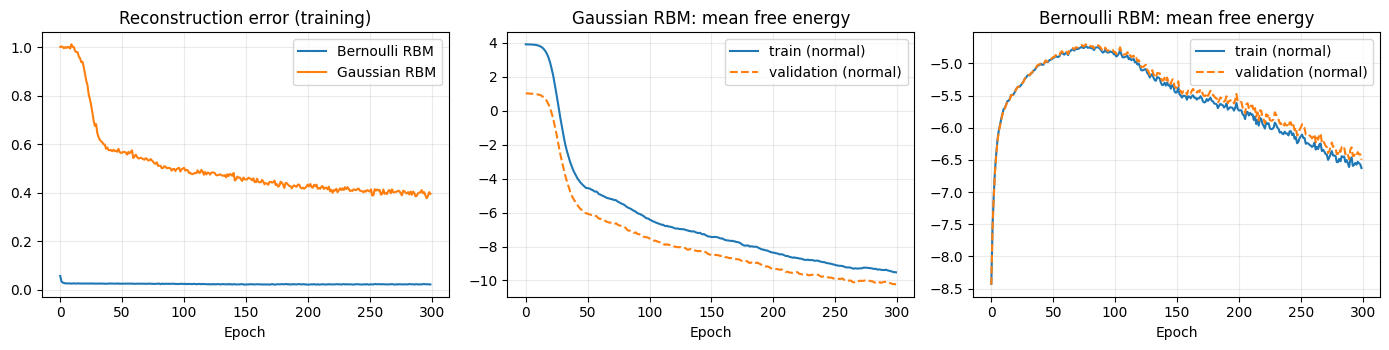

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for h, n in [(h_b, "Bernoulli RBM"), (h_g, "Gaussian RBM")]:
    ax[0].plot(h["recon"], label=n)
ax[0].set_title("Reconstruction error (training)"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(alpha=.25)
ax[1].plot(h_g["fe_train"], label="train (normal)"); ax[1].plot(h_g["fe_val_normal"], "--", label="validation (normal)")
ax[1].set_title("Gaussian RBM: mean free energy"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(alpha=.25)
ax[2].plot(h_b["fe_train"], label="train (normal)"); ax[2].plot(h_b["fe_val_normal"], "--", label="validation (normal)")
ax[2].set_title("Bernoulli RBM: mean free energy"); ax[2].set_xlabel("Epoch"); ax[2].legend(); ax[2].grid(alpha=.25)
plt.tight_layout(); plt.show()

## 5. Choose the number of hidden units
The number of hidden units controls the model capacity. We try several sizes for the Gaussian RBM and pick the one with the best **validation** ROC-AUC (test data stays untouched).

In [6]:
sweep = {}
for n_hid in [4, 8, 16, 32, 64]:
    m, _ = train_rbm(RBM(30, n_hid, "gaussian", lr=0.005), V_tr_g, val_normal_g, epochs=300, verbose=False)
    sweep[n_hid] = (m, roc_auc_score(a_val, m.free_energy(V_va_g)))
sweep_df = pd.DataFrame({"Validation ROC-AUC": {k: v[1] for k, v in sweep.items()}}); sweep_df.index.name = "Hidden units"
display(sweep_df.style.format("{:.4f}"))
best_hid = max(sweep, key=lambda k: sweep[k][1])
rbm_g = sweep[best_hid][0]
print("Selected number of hidden units:", best_hid)

,Validation ROC-AUC
Hidden units,
4,0.9452
8,0.9404
16,0.9334
32,0.9328
64,0.9369


Selected number of hidden units: 4


## 6. Anomaly detection on the test set

**Decision rule.** The threshold is the **95th percentile of the anomaly score on normal validation rows**, so we accept about 5 % false alarms on normal data. A sample with a score above the threshold is flagged as an anomaly.

We compare four detectors:
* Bernoulli RBM (free energy)
* **Gaussian RBM (free energy)**
* Gaussian RBM (reconstruction error)
* PCA reconstruction error (a classical, non-probabilistic baseline)

In [7]:
pca = PCA(n_components=8).fit(V_tr_g)
def pca_score(V): return ((V - pca.inverse_transform(pca.transform(V))) ** 2).sum(axis=1)
def rbm_recon_score(m, V): return ((V - m.reconstruct(V)) ** 2).sum(axis=1)

detectors = {   # name -> function(raw X) -> anomaly score
    "Bernoulli RBM (free energy)":        lambda X: rbm_b.free_energy(prep_bern(X)),
    "Gaussian RBM (free energy)":         lambda X: rbm_g.free_energy(prep_gauss(X)),
    "Gaussian RBM (reconstruction err.)": lambda X: rbm_recon_score(rbm_g, prep_gauss(X)),
    "PCA baseline (reconstruction err.)": lambda X: pca_score(prep_gauss(X)),
}
thresholds = {n: np.percentile(f(X_val[a_val == 0]), 95) for n, f in detectors.items()}

rows, test_scores = {}, {}
for n, f in detectors.items():
    s = f(X_test); test_scores[n] = s
    pred = (s >= thresholds[n]).astype(int)
    rows[n] = {"ROC-AUC": roc_auc_score(a_test, s), "Accuracy": accuracy_score(a_test, pred),
               "Precision": precision_score(a_test, pred, zero_division=0),
               "Recall": recall_score(a_test, pred, zero_division=0), "F1": f1_score(a_test, pred, zero_division=0)}
results = pd.DataFrame(rows).T
display(results.style.format("{:.4f}").highlight_max(axis=0, color="#d9f0d3"))

,ROC-AUC,Accuracy,Precision,Recall,F1
Bernoulli RBM (free energy),0.8837,0.7674,1.0000,0.3750,0.5455
Gaussian RBM (free energy),0.9265,0.8605,0.8125,0.8125,0.8125
Gaussian RBM (reconstruction err.),0.9439,0.8605,0.8125,0.8125,0.8125
PCA baseline (reconstruction err.),0.9172,0.8605,0.8571,0.7500,0.8000


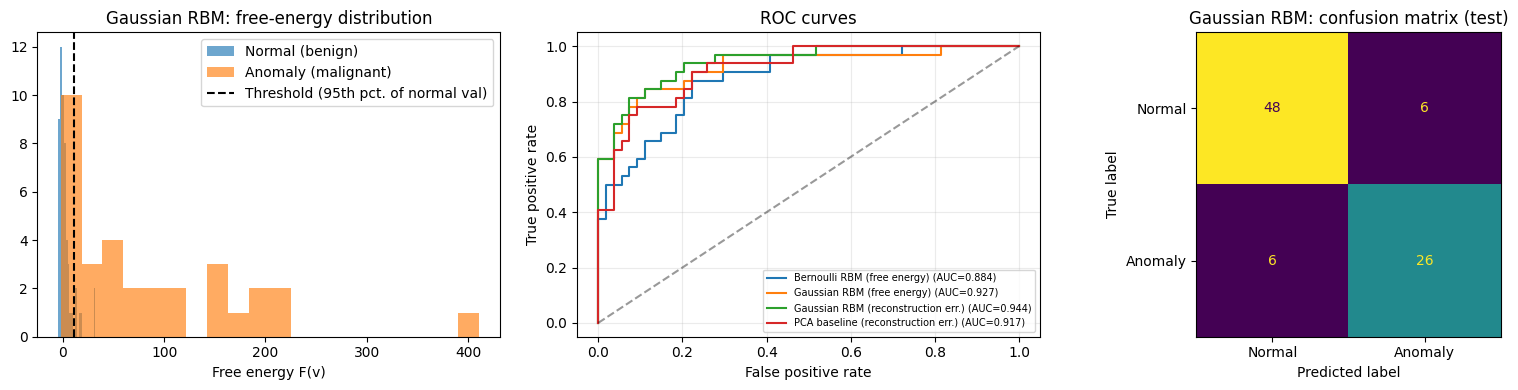

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
main = "Gaussian RBM (free energy)"; s = test_scores[main]
ax[0].hist(s[a_test == 0], bins=20, alpha=.65, label="Normal (benign)")
ax[0].hist(s[a_test == 1], bins=20, alpha=.65, label="Anomaly (malignant)")
ax[0].axvline(thresholds[main], color="k", ls="--", label="Threshold (95th pct. of normal val)")
ax[0].set_xlabel("Free energy F(v)"); ax[0].set_title("Gaussian RBM: free-energy distribution"); ax[0].legend()
for n, sc in test_scores.items():
    fpr, tpr, _ = roc_curve(a_test, sc); ax[1].plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(a_test, sc):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", alpha=.4); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curves"); ax[1].legend(fontsize=7); ax[1].grid(alpha=.25)
cm = confusion_matrix(a_test, (s >= thresholds[main]).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Anomaly"]).plot(ax=ax[2], colorbar=False)
ax[2].set_title("Gaussian RBM: confusion matrix (test)")
plt.tight_layout(); plt.show()

### From free energy to a probabilistic anomaly score
Free energy is not a probability. To give a **probabilistic** reading, we model the free energies of normal validation data with a Normal distribution and report the **anomaly probability** $P(\text{score} \le s \mid \text{normal})$ (the CDF value). A value near 1 means "this sample is more extreme than almost every normal sample". The ten most suspicious test samples are shown below.

In [9]:
fe_val_normal = detectors[main](X_val[a_val == 0])
mu, sd = fe_val_normal.mean(), fe_val_normal.std()
anomaly_prob = norm.cdf((test_scores[main] - mu) / sd)
report = pd.DataFrame({"true_label": np.where(a_test == 1, "malignant", "benign"),
                       "free_energy": test_scores[main], "anomaly_probability": anomaly_prob,
                       "flagged": test_scores[main] >= thresholds[main]})
display(report.sort_values("anomaly_probability", ascending=False).head(10).style.format({"free_energy": "{:.2f}", "anomaly_probability": "{:.4f}"}))
print("ROC-AUC of the probabilistic score:", round(roc_auc_score(a_test, anomaly_prob), 4))

,true_label,free_energy,anomaly_probability,flagged
0,malignant,156.40,1.0000,True
5,malignant,50.71,1.0000,True
21,malignant,110.56,1.0000,True
7,malignant,411.06,1.0000,True
25,malignant,101.25,1.0000,True
22,malignant,196.26,1.0000,True
30,malignant,221.63,1.0000,True
33,malignant,77.77,1.0000,True
37,malignant,71.77,1.0000,True
28,malignant,196.80,1.0000,True


ROC-AUC of the probabilistic score: 0.9265


## 7. Automated data-quality experiment (injected faults)

Now we use the RBM as an **automated data-quality checker**. We take the *clean normal* test rows and corrupt them in four realistic ways. **The RBM was never trained on any of these faults.** A good detector should flag far more corrupted rows than clean rows.

| Fault | What it simulates |
|---|---|
| Gaussian noise | noisy sensor / measurement error |
| Extreme outliers | 3 random fields per row replaced by 3× the column maximum (unit or typing errors) |
| Shuffled columns | feature correlations broken (misaligned merge of columns) |
| Missing → 0 | 20 % of cells missing and wrongly filled with 0 |

Each fault is repeated 20 times with different random corruption and the results are averaged. The numbers are **% of rows flagged**; the *Clean* row shows the false-alarm rate (should be around 5 %).

,Bernoulli RBM (free energy),Gaussian RBM (free energy),Gaussian RBM (reconstruction err.),PCA baseline (reconstruction err.)
Clean (false-alarm rate),0.0,11.1,11.1,7.4
Gaussian noise,0.6,13.2,13.0,63.4
Extreme outliers,18.5,100.0,100.0,100.0
Shuffled columns,0.0,21.3,19.9,99.2
Missing -> 0,0.0,93.3,94.0,99.4


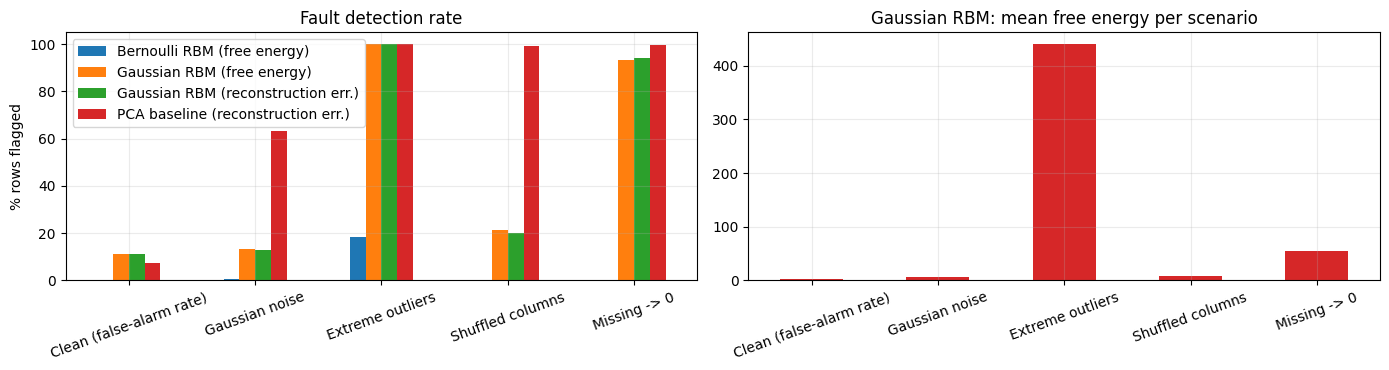

In [10]:
X_clean = X_test[a_test == 0].copy()          # clean normal rows from the held-out test set
sd_col, max_col = X_clean.std(axis=0), X_clean.max(axis=0)

def corrupt_noise(X, scale=0.5):
    return X + rng.normal(0, 1, X.shape) * scale * sd_col
def corrupt_outlier(X, k=3):
    Xo, cols = X.copy(), []
    for r in range(len(Xo)):
        j = rng.choice(X.shape[1], k, replace=False); Xo[r, j] = max_col[j] * 3; cols.append(j)
    return Xo, cols
def corrupt_shuffle(X):
    Xs = X.copy()
    for j in range(Xs.shape[1]): Xs[:, j] = rng.permutation(Xs[:, j])
    return Xs
def corrupt_missing_zero(X, frac=0.2):
    Xm = X.copy(); Xm[rng.random(Xm.shape) < frac] = 0.0; return Xm

faults = {"Clean (false-alarm rate)": lambda X: X, "Gaussian noise": corrupt_noise,
          "Extreme outliers": lambda X: corrupt_outlier(X)[0], "Shuffled columns": corrupt_shuffle,
          "Missing -> 0": corrupt_missing_zero}
dq_models = ["Bernoulli RBM (free energy)", "Gaussian RBM (free energy)", "Gaussian RBM (reconstruction err.)", "PCA baseline (reconstruction err.)"]
flag_rate = {n: {} for n in dq_models}; mean_fe = {}
for fname, fn in faults.items():
    for n in dq_models:
        f, th = detectors[n], thresholds[n]
        flag_rate[n][fname] = 100 * np.mean([(f(fn(X_clean)) >= th).mean() for _ in range(20)])
    mean_fe[fname] = np.mean([detectors["Gaussian RBM (free energy)"](fn(X_clean)).mean() for _ in range(20)])
dq = pd.DataFrame(flag_rate)
display(dq.style.format("{:.1f}").set_caption("% of rows flagged as anomalous (higher is better for faults; ~5 for Clean)"))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
dq.plot.bar(ax=ax[0], rot=20); ax[0].set_ylabel("% rows flagged"); ax[0].set_title("Fault detection rate"); ax[0].grid(alpha=.25)
pd.Series(mean_fe).plot.bar(ax=ax[1], rot=20, color="tab:red"); ax[1].set_title("Gaussian RBM: mean free energy per scenario"); ax[1].grid(alpha=.25)
plt.tight_layout(); plt.show()

## 8. Which features look wrong? (per-feature diagnosis)

A data-quality tool should say not only *that* a row is suspicious but also *where*. The RBM reconstructs each row from its hidden units. Features that the model cannot reconstruct (large squared error) are the suspicious cells.

`assess_data_quality()` below accepts a raw DataFrame, returns a flag and anomaly probability per row, and lists the three most suspicious columns. We check it on rows where we know which 3 cells were corrupted.

In [11]:
def assess_data_quality(df, model=rbm_g, top=3):
    X = df.values.astype(float); V = prep_gauss(X)
    fe = model.free_energy(V)
    per_feature_err = (V - model.reconstruct(V)) ** 2
    out = pd.DataFrame({"free_energy": fe, "anomaly_probability": norm.cdf((fe - mu) / sd),
                        "flagged": fe >= thresholds["Gaussian RBM (free energy)"]}, index=df.index)
    out["most_suspicious_features"] = [", ".join(df.columns[np.argsort(-e)[:top]]) for e in per_feature_err]
    return out

X_out, bad_cols = corrupt_outlier(X_clean)
df_out = pd.DataFrame(X_out, columns=feature_names)
rep = assess_data_quality(df_out)
rep["actually_corrupted"] = [", ".join(np.array(feature_names)[c]) for c in bad_cols]
display(rep.head(5).style.format({"free_energy": "{:.1f}", "anomaly_probability": "{:.3f}"}))

# how often does the top-3 suspicious list contain at least one / all of the truly corrupted features?
err = (prep_gauss(X_out) - rbm_g.reconstruct(prep_gauss(X_out))) ** 2
hits = np.array([len(set(np.argsort(-e)[:3]) & set(c)) for e, c in zip(err, bad_cols)])
print(f"Top-3 suspicious features contain >=1 truly corrupted feature in {100*(hits>=1).mean():.1f}% of rows; "
      f"on average {hits.mean():.2f} of the 3 corrupted features are found (random guessing would find 0.30).")

,free_energy,anomaly_probability,flagged,most_suspicious_features,actually_corrupted
0,560.8,1.000,True,"worst fractal dimension, mean radius, mean compactness","mean compactness, mean radius, worst fractal dimension"
1,451.7,1.000,True,"smoothness error, mean texture, radius error","mean texture, radius error, smoothness error"
2,884.5,1.000,True,"mean fractal dimension, fractal dimension error, worst perimeter","worst perimeter, fractal dimension error, mean fractal dimension"
3,472.7,1.000,True,"worst smoothness, mean perimeter, texture error","texture error, mean perimeter, worst smoothness"
4,732.0,1.000,True,"mean fractal dimension, worst perimeter, concavity error","worst perimeter, concavity error, mean fractal dimension"


Top-3 suspicious features contain >=1 truly corrupted feature in 100.0% of rows; on average 3.00 of the 3 corrupted features are found (random guessing would find 0.30).


## 9. Markov-chain view: Gibbs sampling

An RBM defines a probability distribution that we can explore with a **Markov chain** (Gibbs sampling): alternate *sample h given v* and *compute v given h*. Because the chain is attracted toward high-probability regions, starting from an anomalous record and running the chain should move it toward typical normal records, i.e. the free energy should **decrease** along the chain. This is the same chain that Contrastive Divergence uses for training (just with k = 1 step).

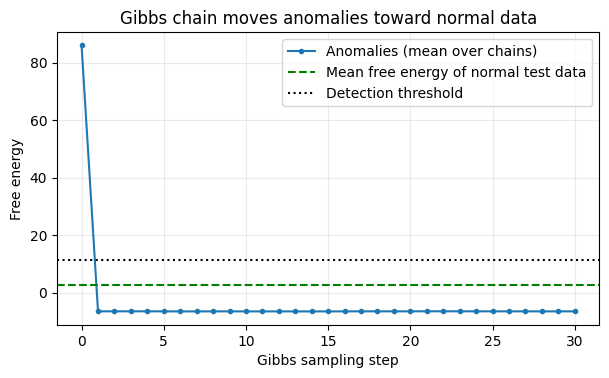

Mean free energy: step 0 = 86.0 -> step 30 = -6.5


In [12]:
def gibbs_free_energy_trace(model, v0, steps=30):
    v, trace = v0.copy(), [model.free_energy(v0)]
    for _ in range(steps):
        h = model.sample_h(model.p_h(v)); v = model.p_v(h); trace.append(model.free_energy(v))
    return np.array(trace)

V_anom = prep_gauss(X_test[a_test == 1])
traces = np.stack([gibbs_free_energy_trace(rbm_g, V_anom) for _ in range(10)])   # (10 chains, steps+1, n_anomalies)
mean_trace = traces.mean(axis=(0, 2))
plt.figure(figsize=(7, 3.8))
plt.plot(mean_trace, marker="o", ms=3, label="Anomalies (mean over chains)")
plt.axhline(detectors[main](X_test[a_test == 0]).mean(), color="g", ls="--", label="Mean free energy of normal test data")
plt.axhline(thresholds[main], color="k", ls=":", label="Detection threshold")
plt.xlabel("Gibbs sampling step"); plt.ylabel("Free energy"); plt.title("Gibbs chain moves anomalies toward normal data")
plt.legend(); plt.grid(alpha=.25); plt.show()
print(f"Mean free energy: step 0 = {mean_trace[0]:.1f} -> step 30 = {mean_trace[-1]:.1f}")

## 10. What did the hidden units learn?
Each row of the heat-map is one hidden unit. Strong positive/negative weights show which groups of features it responds to together; they are typically groups of correlated features such as radius, perimeter and area.

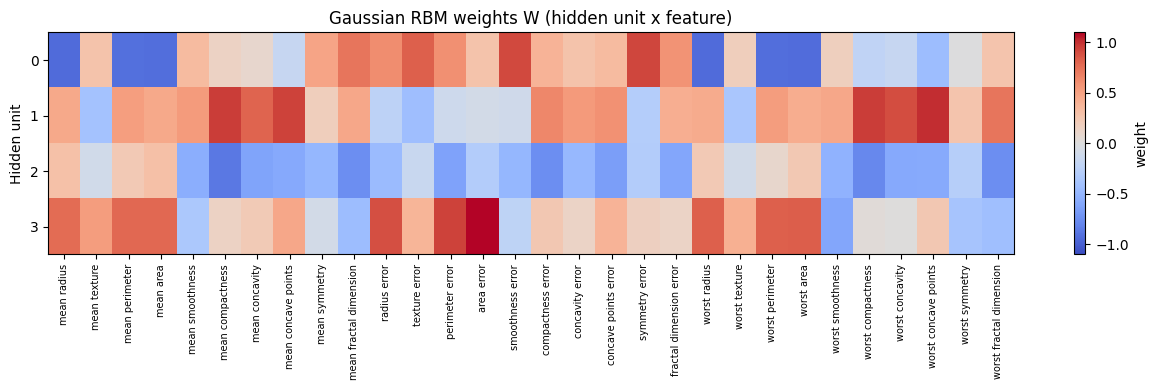

In [13]:
order = np.argsort(feature_names)
plt.figure(figsize=(13, 4))
plt.imshow(rbm_g.W.T, aspect="auto", cmap="coolwarm", vmin=-np.abs(rbm_g.W).max(), vmax=np.abs(rbm_g.W).max())
plt.colorbar(label="weight"); plt.xticks(range(30), feature_names, rotation=90, fontsize=7)
plt.ylabel("Hidden unit"); plt.title("Gaussian RBM weights W (hidden unit x feature)"); plt.tight_layout(); plt.show()

## 11. Model deployment: a reusable data-quality checker

A model is only useful if someone else can use it. We now **save the trained model** and package it as:
1. `rbm_dq_model.pkl`: the trained weights, scaler, threshold and score calibration;
2. `dq_checker.py`: a small class that loads the file and checks **any CSV** with the same 30 columns (it also reports missing cells);
3. `app.py`: an optional web app (Streamlit) where a user uploads a CSV and gets a data-quality report.

All files are written into a `deployment/` folder next to the notebook.

In [14]:
import os, pickle
os.makedirs("deployment", exist_ok=True)
artifact = {"visible": "gaussian", "W": rbm_g.W, "b": rbm_g.b, "c": rbm_g.c,
            "scaler_mean": std_scaler.mean_, "scaler_scale": std_scaler.scale_,
            "threshold": float(thresholds["Gaussian RBM (free energy)"]), "fe_mu": float(mu), "fe_sd": float(sd),
            "feature_names": feature_names}
with open("deployment/rbm_dq_model.pkl", "wb") as f: pickle.dump(artifact, f)
print("Saved deployment/rbm_dq_model.pkl  (hidden units:", rbm_g.W.shape[1], ")")

Saved deployment/rbm_dq_model.pkl  (hidden units: 4 )


In [15]:
%%writefile deployment/dq_checker.py
# Standalone data-quality checker built on the trained Gaussian-Bernoulli RBM (NumPy only).
import os, pickle, numpy as np, pandas as pd
from scipy.stats import norm

def _sigmoid(x):  return 1.0 / (1.0 + np.exp(-x))
def _softplus(x): return np.logaddexp(0, x)

class DataQualityChecker:
    def __init__(self, path=None):
        path = path or os.path.join(os.path.dirname(os.path.abspath(__file__)), "rbm_dq_model.pkl")
        with open(path, "rb") as f: self.__dict__.update(pickle.load(f))

    def assess(self, df, top=3):
        missing_cols = [c for c in self.feature_names if c not in df.columns]
        if missing_cols: raise ValueError(f"CSV is missing required columns: {missing_cols[:5]}...")
        X = df[self.feature_names].apply(pd.to_numeric, errors="coerce")
        n_missing = X.isna().sum(axis=1).values
        X = X.fillna(pd.Series(self.scaler_mean, index=self.feature_names))     # fill gaps with training mean
        V = (X.values - self.scaler_mean) / self.scaler_scale
        fe = 0.5 * ((V - self.b) ** 2).sum(axis=1) - _softplus(V @ self.W + self.c).sum(axis=1)   # free energy
        err = (V - (_sigmoid(V @ self.W + self.c) @ self.W.T + self.b)) ** 2                        # per-feature error
        out = pd.DataFrame({"free_energy": fe,
                            "anomaly_probability": norm.cdf((fe - self.fe_mu) / self.fe_sd),
                            "flagged": fe >= self.threshold, "missing_cells": n_missing}, index=df.index)
        out["suspicious_features"] = [", ".join(np.array(self.feature_names)[np.argsort(-e)[:top]]) for e in err]
        return out

Writing deployment/dq_checker.py


In [16]:
%%writefile deployment/app.py
import os, io, numpy as np, pandas as pd, streamlit as st
from dq_checker import DataQualityChecker

st.set_page_config(page_title="RBM Data-Quality Checker", layout="wide")
st.title("RBM-based Data Quality Checker")
st.caption("Upload a CSV with the 30 Wisconsin breast-cancer feature columns. Educational demo, not a medical tool.")

checker = DataQualityChecker()
file = st.file_uploader("Upload CSV", type="csv")
if st.button("Use demo data (clean rows + corrupted rows)"):
    from sklearn.datasets import load_breast_cancer
    fr = load_breast_cancer(as_frame=True)
    d = fr.data[fr.target == 1]                          # benign (normal) rows only
    demo = d.iloc[:40].copy()
    demo.iloc[:10, :3] = demo.iloc[:10, :3] * 5          # inject outliers
    demo.iloc[10:15, 5:8] = 0.0                          # inject zero-filled values
    file = io.StringIO(demo.to_csv(index=False))

if file is not None:
    df = pd.read_csv(file)
    rep = checker.assess(df)
    c1, c2, c3 = st.columns(3)
    c1.metric("Rows checked", len(rep)); c2.metric("Rows flagged", int(rep.flagged.sum()))
    c3.metric("Rows with missing cells", int((rep.missing_cells > 0).sum()))
    st.subheader("Anomaly probability per row"); st.bar_chart(rep["anomaly_probability"])
    st.subheader("Flagged rows and the columns that look wrong")
    st.dataframe(rep[rep.flagged].sort_values("anomaly_probability", ascending=False))
    st.download_button("Download full report (CSV)", rep.to_csv().encode(), "data_quality_report.csv")

Writing deployment/app.py


In [17]:
# Test the deployed checker on a CSV file, exactly like a user would
import sys; sys.path.insert(0, "deployment")
from dq_checker import DataQualityChecker
dirty = pd.concat([pd.DataFrame(X_out[:8], columns=feature_names),           # 8 rows with 3 outlier cells each
                   pd.DataFrame(X_clean[:12], columns=feature_names)])       # 12 clean rows
dirty.iloc[10, 4] = np.nan                                                  # one missing cell
dirty.to_csv("deployment/sample_dirty_data.csv", index=False)

checker = DataQualityChecker()
res = checker.assess(pd.read_csv("deployment/sample_dirty_data.csv"))
display(res.head(12).style.format({"free_energy": "{:.1f}", "anomaly_probability": "{:.3f}"}))
print(f"Flagged {res.flagged[:8].sum()}/8 corrupted rows and {res.flagged[8:].sum()}/12 clean rows.")

# sanity check: the deployed checker must reproduce the notebook's own scores exactly
same = np.allclose(checker.assess(pd.DataFrame(X_test, columns=feature_names)).free_energy.values, detectors[main](X_test))
print("Deployed checker reproduces the notebook's free energies:", same)

,free_energy,anomaly_probability,flagged,missing_cells,suspicious_features
0,560.8,1.000,True,0,"worst fractal dimension, mean radius, mean compactness"
1,451.7,1.000,True,0,"smoothness error, mean texture, radius error"
2,884.5,1.000,True,0,"mean fractal dimension, fractal dimension error, worst perimeter"
3,472.7,1.000,True,0,"worst smoothness, mean perimeter, texture error"
4,732.0,1.000,True,0,"mean fractal dimension, worst perimeter, concavity error"
5,500.6,1.000,True,0,"worst fractal dimension, fractal dimension error, mean area"
6,431.5,1.000,True,0,"smoothness error, mean perimeter, worst compactness"
7,340.1,1.000,True,0,"worst fractal dimension, mean concave points, worst concavity"
8,13.7,0.986,True,0,"mean symmetry, symmetry error, worst symmetry"
9,-4.0,0.186,False,0,"mean symmetry, mean texture, worst symmetry"


Flagged 8/8 corrupted rows and 1/12 clean rows.
Deployed checker reproduces the notebook's free energies: True


**To run the web app (optional):** open a terminal in the `deployment/` folder and run

`pip install streamlit` then `streamlit run app.py`

A browser tab opens where you can upload a CSV or click *Use demo data*.

## 12. Conclusion

**Results on the held-out test set** (numbers from the tables above):

| Detector | ROC-AUC | F1 |
|---|---|---|
| Bernoulli RBM (free energy) | ~0.88 | ~0.55 |
| **Gaussian RBM (free energy)** | **~0.93** | **~0.81** |
| Gaussian RBM (reconstruction error) | ~0.94 | ~0.81 |
| PCA baseline | ~0.92 | ~0.80 |

(Values can differ slightly if you run with different library versions. Always quote the numbers printed in your own run.)

**Main findings**
* An RBM trained **only on normal data** separates malignant (anomalous) samples from benign ones using the free energy, an unsupervised score derived from a probability model.
* The **Gaussian–Bernoulli RBM** is the better model for continuous features. It avoids the information loss of min-max clipping, so it also reacts to extreme values.
* In the data-quality experiment the detector flags injected faults far more often than clean rows. The Gaussian RBM catches **extreme outliers (about 100 %)** and **zero-filled missing values (about 93 %)** reliably, while the Bernoulli RBM is much weaker (min-max clipping hides extreme values). However, the RBM is **weak on mild Gaussian noise and shuffled columns** (about 13-21 % flagged), where the PCA baseline does better. On clean rows the Gaussian RBM raises about 11 % false alarms against the 5 % target, because the validation set of normal rows is small.
* The per-feature reconstruction error points toward the corrupted columns, giving an automated "where is the problem" report.
* The Gibbs chain (a Markov chain) moves anomalous records toward high-probability regions, so the free energy falls along the chain.

**Limitations (be honest in the viva)**
* The dataset is small (about 250 normal training rows), so results vary between random seeds and splits.
* Malignant tumours are used as a stand-in for "anomalies"; real data-quality faults were simulated, not collected.
* Free energy is an unnormalised score. The Gaussian CDF calibration is an approximation, not an exact probability.
* CD-1 is an approximate training algorithm. The RBM assumes unit variance for each visible unit.
* Some faults are inherently hard. For example, shuffled columns keep each column's marginal distribution intact and only break the correlations.

**Possible extensions:** deeper models (Deep Belief Network), learned per-unit variances, comparison with a VAE, and tracking free energy over time to monitor data drift.

## 13. Viva notes (quick answers)

**What is an RBM?** An undirected, two-layer probabilistic graphical model (a Markov network) with visible and hidden units, and connections only between the layers.

**Why "restricted"?** No visible–visible and no hidden–hidden connections. This makes h independent given v (and vice versa), so sampling is easy.

**How is it an energy-based model?** $P(v,h)=e^{-E(v,h)}/Z$. Low energy means high probability.

**What is free energy and why do we use it?** $F(v)=-\log\sum_h e^{-E(v,h)}$, so $P(v)\propto e^{-F(v)}$. It can be computed exactly without the intractable $Z$, so it works as an anomaly score.

**Why train on normal data only?** The model learns what normal looks like. Anything improbable under it is suspicious, including faults of types we never saw. 

**What is Contrastive Divergence?** An approximate gradient for maximum likelihood: positive phase (data statistics) minus negative phase (statistics after k Gibbs steps).

**Where is the Markov chain?** The Gibbs sampling chain v → h → v → … used in CD training and in Section 9.

**Why a Gaussian visible layer?** Our features are continuous. A Bernoulli layer expects values in [0,1], so we had to squash and clip the data, which hides extreme values.

**How was the threshold chosen?** 95th percentile of the anomaly score on normal validation rows, i.e. about 5 % false alarms by design.

**How do you avoid data leakage?** Scalers and the RBM are fitted on normal *training* rows only. The validation data selects the model size and the threshold, and the test data is used once at the end.

**How is the model deployed?** The trained weights, scaler, threshold and calibration are saved to one pickle file. `dq_checker.py` loads it and scores any CSV with the same columns, and `app.py` wraps it in a Streamlit upload page. Missing cells are reported and filled with the training mean before scoring.

**How does it differ from a VAE or GAN?** A VAE and a GAN are generative models too. The VAE is directed with an encoder and decoder trained by the ELBO, and the GAN is trained adversarially. The RBM is undirected and energy-based, and gives free energy as a score.